# Diagnóstico de Burgers: precisión, residuo y selección de puntos

**Pregunta:** ¿por qué POD/PCA reduce el residuo, pero empeora la solución frente a Sobol? Este notebook observa el entrenamiento y distingue mediciones de hipótesis. No cambia la pérdida ni el selector.

Se repiten Sobol, POD con 32 puntos y PCA centrado + media con 64 puntos, en 10 semillas, con 100 pasos de calentamiento y 2000 de continuación. El lote físico tiene 128 puntos y se actualiza cada 100 pasos. Los puntos guiados usan QR inicial y ampliación log-det; el complemento es Sobol. La mayor diferencia absoluta frente a las cinco métricas finales guardadas anteriormente es **0**. La instrumentación reproduce el entrenamiento de referencia.

Los mapas corresponden a la semilla **2051**, fijada en la configuración antes de correr. Las curvas y tablas agregan todas las semillas; las bandas muestran desviación estándar entre semillas, salvo las curvas logarítmicas de pérdidas y normas, que usan percentiles 16–84 empíricos. No son intervalos de confianza. La mayor diferencia entre los monitores de las trayectorias repetidas y las originales es **0**.

## 1. La pérdida que realmente se está entrenando

\[L=L_{datos}+L_{física}+L_{IC},\qquad L_{física}=\frac1{128}\sum r_\theta(x_i,t_i)^2.\]

Los tres pesos son 1. Datos usa minibatches de los tiempos de ajuste; IC compara u(x,0) en el subconjunto espacial configurado. **No hay una penalización separada de frontera en esta pérdida.** Los datos supervisados pueden incluir nodos de frontera; además, esta se monitoriza para evaluar el modelo.

**Hallazgo del protocolo:** `initial_ids = arange(initial_condition_points)` impone IC en los primeros **32 de 256 nodos**, entre x=-1.0000 y x=-0.7569. Su intervalo cubre aproximadamente **12.2%** del ancho espacial. Una L_IC pequeña en esa zona no demuestra que IC sea correcta en todo el dominio. Los datos supervisados también pueden contener t=0, pero su muestreo cambia entre minibatches.

Este diagnóstico conserva ese protocolo para reproducir las corridas previas. La franja amarilla del perfil t=0 muestra los nodos de IC impuestos explícitamente.

## 2. Qué datos intervienen en cada medición

| Medición | Puntos y uso |
|---|---|
| Sonda común | 128 puntos físicos Sobol fijos, distintos de candidatos y evaluación; mismos puntos para todos los métodos de una semilla. |
| Sonda activa | Los mismos datos e IC de la sonda común; solo se sustituyen las coordenadas físicas por el lote activo del método. |
| Datos de las sondas | Un minibatch supervisado congelado de tiempos de ajuste, igual en todos los métodos y controles; no se añaden datos de prueba al entrenamiento. |
| Error de solución y regiones | Tiempos de prueba reservados por semilla; el mismo conjunto para los tres métodos. |
| Residuo independiente | 2048 puntos Sobol fuera del candidato y de la selección. |
| Mapas y perfiles | Malla de referencia con tiempos de ajuste, validación y prueba; visualización exploratoria, no métrica de generalización. |

Las sondas se calculan después de cada control de entrenamiento, incluido el calentamiento en paso 100. La sonda activa usa el lote del intervalo recién terminado; se guarda `active_selection_step`. Las pérdidas de las sondas no son el último minibatch aleatorio del optimizador.

## 3. Resultado global y localización del error

| Método | RMSE prueba | Residuo RMS independiente | RMSE IC global | RMS frontera |
|---|---:|---:|---:|---:|
| Sobol | 0.1800 ± 0.0359 | 0.3664 ± 0.1474 | 0.2235 ± 0.0235 | 0.1262 ± 0.0122 |
| POD: 32 puntos | 0.2124 ± 0.0554 | 0.1236 ± 0.0141 | 0.2525 ± 0.0292 | 0.1170 ± 0.0119 |
| PCA + media: 64 puntos | 0.2298 ± 0.0572 | 0.1241 ± 0.0159 | 0.2656 ± 0.0286 | 0.1054 ± 0.0120 |

Todos los valores son media ± DE entre semillas. El residuo es RMS, las pérdidas físicas posteriores son MSE; no deben confundirse.

Se fija una ventana de inspección **|x| ≤ 0.1 y t ≥ 0.4** para examinar el frente central tardío. No es un detector aprendido de shock y no interviene en el selector. La región exterior es su complemento, incluidos los tiempos anteriores.

| Método | RMSE en ventana central tardía | RMSE fuera de la ventana |
|---|---:|---:|
| Sobol | 0.3736 ± 0.0976 | 0.1579 ± 0.0293 |
| POD: 32 puntos | 0.4352 ± 0.1588 | 0.1873 ± 0.0433 |
| PCA + media: 64 puntos | 0.4699 ± 0.1672 | 0.2022 ± 0.0441 |


**Solución de referencia**

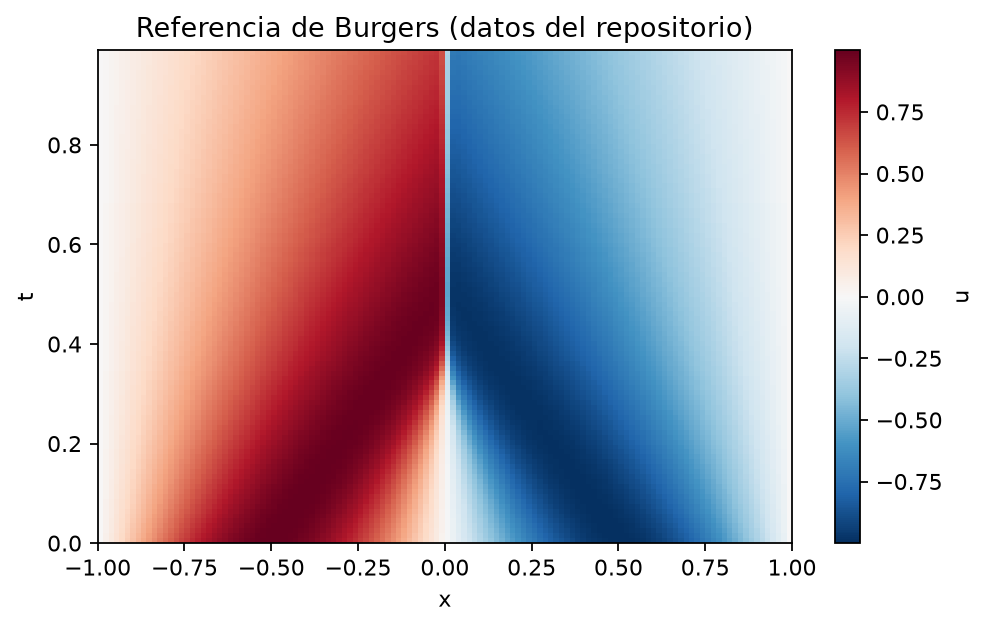

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/reference_solution.png'), format='png', embed=True))


**Solución predicha, error absoluto y residuo final**

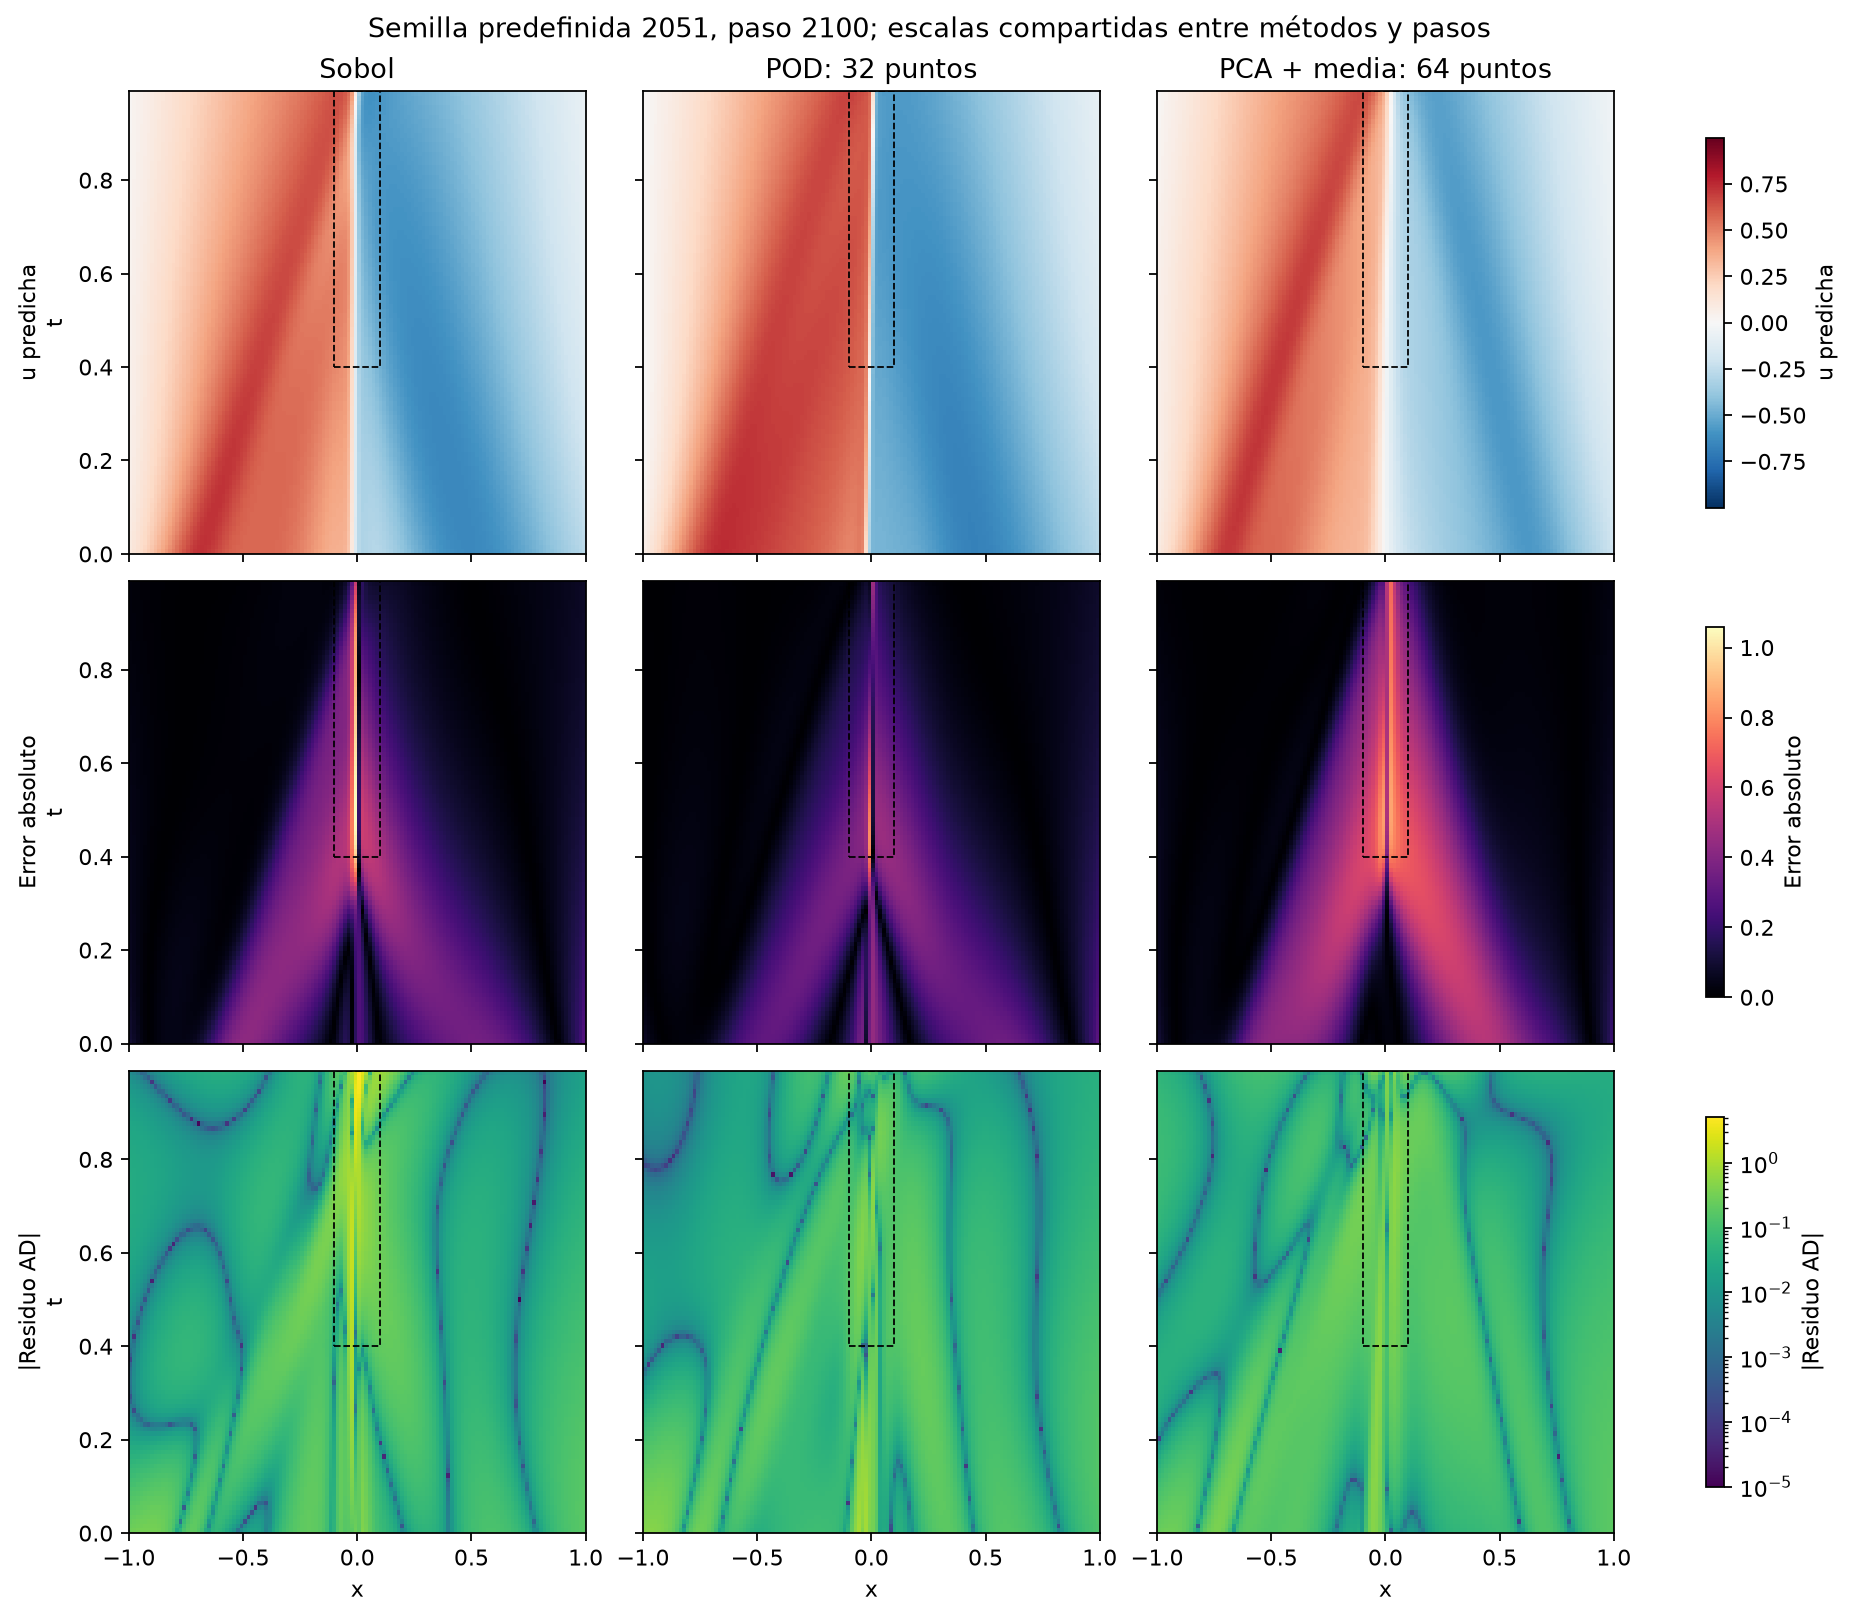

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/fields_step_2100.png'), format='png', embed=True))


Las escalas de color son comunes entre métodos y checkpoints; la escala de |r| es logarítmica y solo su dibujo se recorta por debajo de 1e−5. El residuo de las redes se calcula por autodiferenciación; no se obtiene diferenciando numéricamente los datos. La malla finita puede subrepresentar un frente muy estrecho; las métricas independientes permanecen en los CSV.

**Perfiles finales y zoom alrededor del frente**

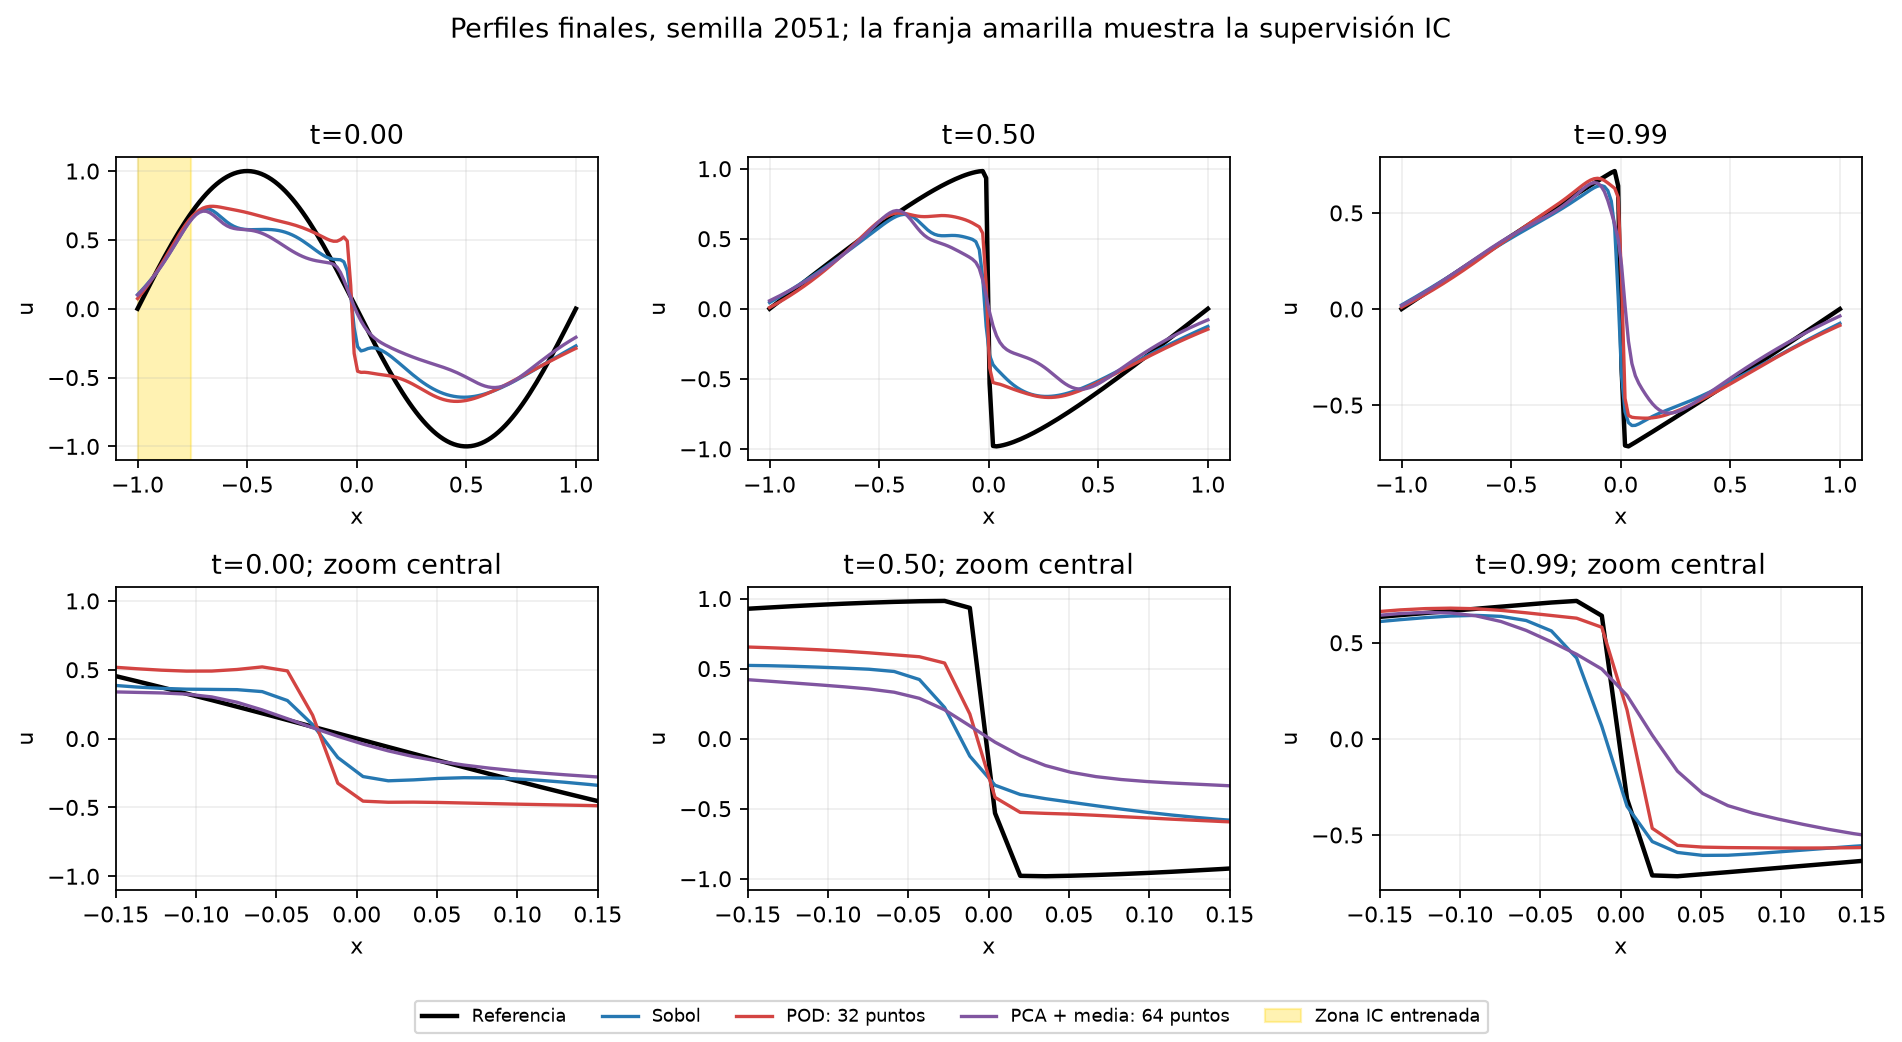

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/solution_profiles.png'), format='png', embed=True))


## 4. Qué términos de la pérdida bajan y dónde

| Método | L datos (común) | L física (común) | L IC en nodos entrenados | L física común / activa |
|---|---:|---:|---:|
| Sobol | 0.0302 ± 0.0114 | 0.0990 ± 0.0955 | 0.0022 ± 0.0009 | 10.5719 ± 11.0950 |
| POD: 32 puntos | 0.0455 ± 0.0198 | 0.0164 ± 0.0055 | 0.0021 ± 0.0010 | 1.1518 ± 0.6044 |
| PCA + media: 64 puntos | 0.0529 ± 0.0239 | 0.0154 ± 0.0040 | 0.0026 ± 0.0019 | 0.9477 ± 0.1612 |

Valores al último checkpoint. Una razón física común/activa mayor que 1 significa que el residuo MSE es mayor en la sonda común que en los puntos activos. Es un contraste entre dos muestras de 128 puntos, no una prueba de sobreajuste ni un reemplazo del residuo independiente de 2048 puntos.

Las filas de datos e IC coinciden entre sondas por construcción: sus puntos son idénticos. La física es la única parte que cambia de ubicaciones. En las curvas logarítmicas, la línea es la media aritmética y la banda muestra percentiles 16–84 de los valores positivos observados; se evita recortar una banda media−DE negativa a un número arbitrario cercano a cero.

**Pérdidas separadas en las sondas común y activa**

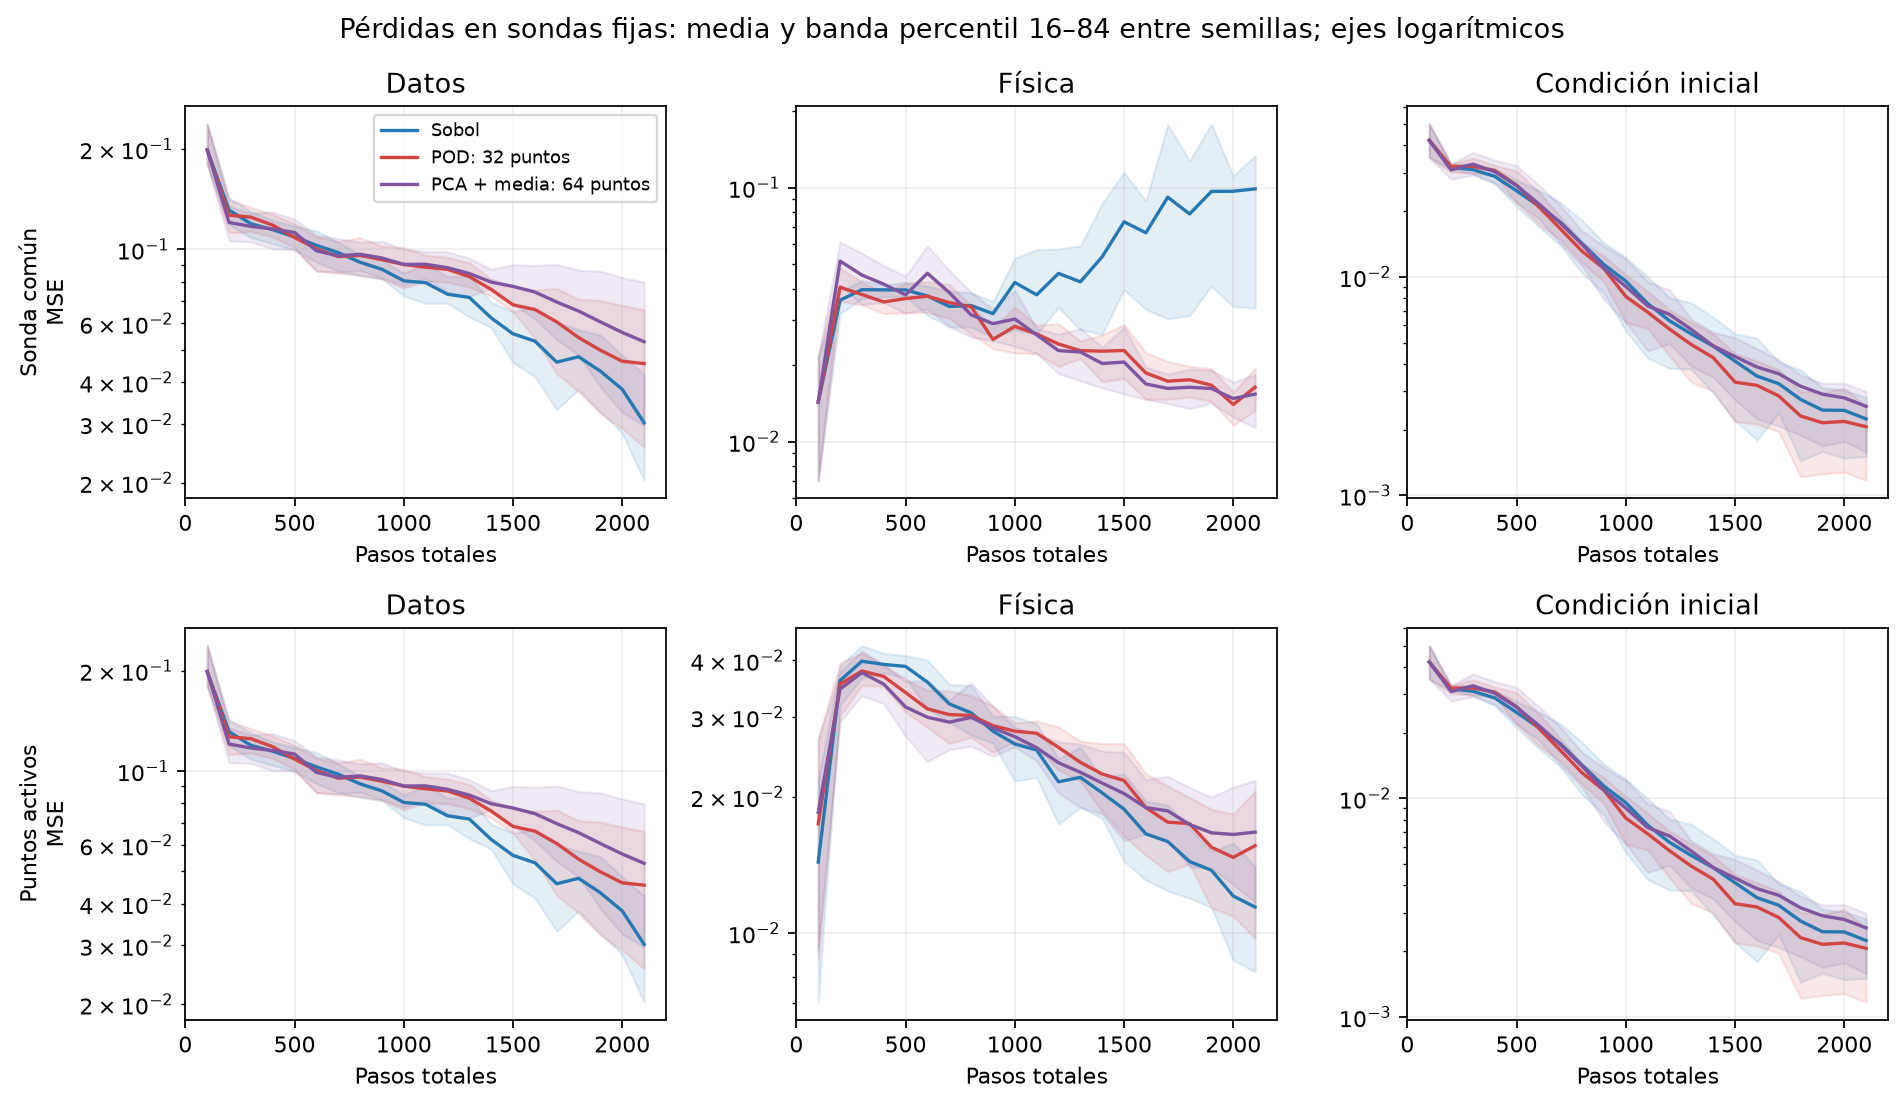

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/loss_components.png'), format='png', embed=True))


## 5. Tamaño y oposición de los gradientes

Se calcula el gradiente de cada término respecto a todos los parámetros de la misma red, con los pesos de entrenamiento 1. La norma L2 mide su tamaño en coordenadas de parámetros; una pérdida pequeña puede tener un gradiente grande.

\[c=\frac{\nabla L_{física}^{T}\nabla(L_{datos}+L_{IC})}{\|\nabla L_{física}\|\,\|\nabla(L_{datos}+L_{IC})\|}.\]

c < 0 indica oposición local entre esos gradientes; c > 0 indica alineación local. El cociente de normas compara la física con el gradiente conjunto de datos e IC. La frecuencia de conflicto se calcula por semilla sobre controles posteriores al calentamiento y luego se resume entre semillas. No se tratan los controles temporales como réplicas independientes.

| Método | Norma ∇L física / norma ∇(L datos + L IC) | Coseno física vs datos + IC | Fracción de controles con conflicto |
|---|---:|---:|---:|
| Sobol | 19.2044 ± 21.4112 | -0.2329 ± 0.5199 | 0.9350 ± 0.0626 |
| POD: 32 puntos | 2.9519 ± 4.6239 | -0.5287 ± 0.3845 | 0.9950 ± 0.0158 |
| PCA + media: 64 puntos | 1.0020 ± 0.2906 | -0.7681 ± 0.1744 | 1.0000 ± 0.0000 |

La tabla usa la **sonda común**, para evitar atribuir al modelo un cambio causado solamente por cambiar los puntos. Son gradientes euclídeos sin el precondicionamiento ni los momentos de Adam: no equivalen a la contribución efectiva de cada término al paso del optimizador.

**Normas de gradiente por término**

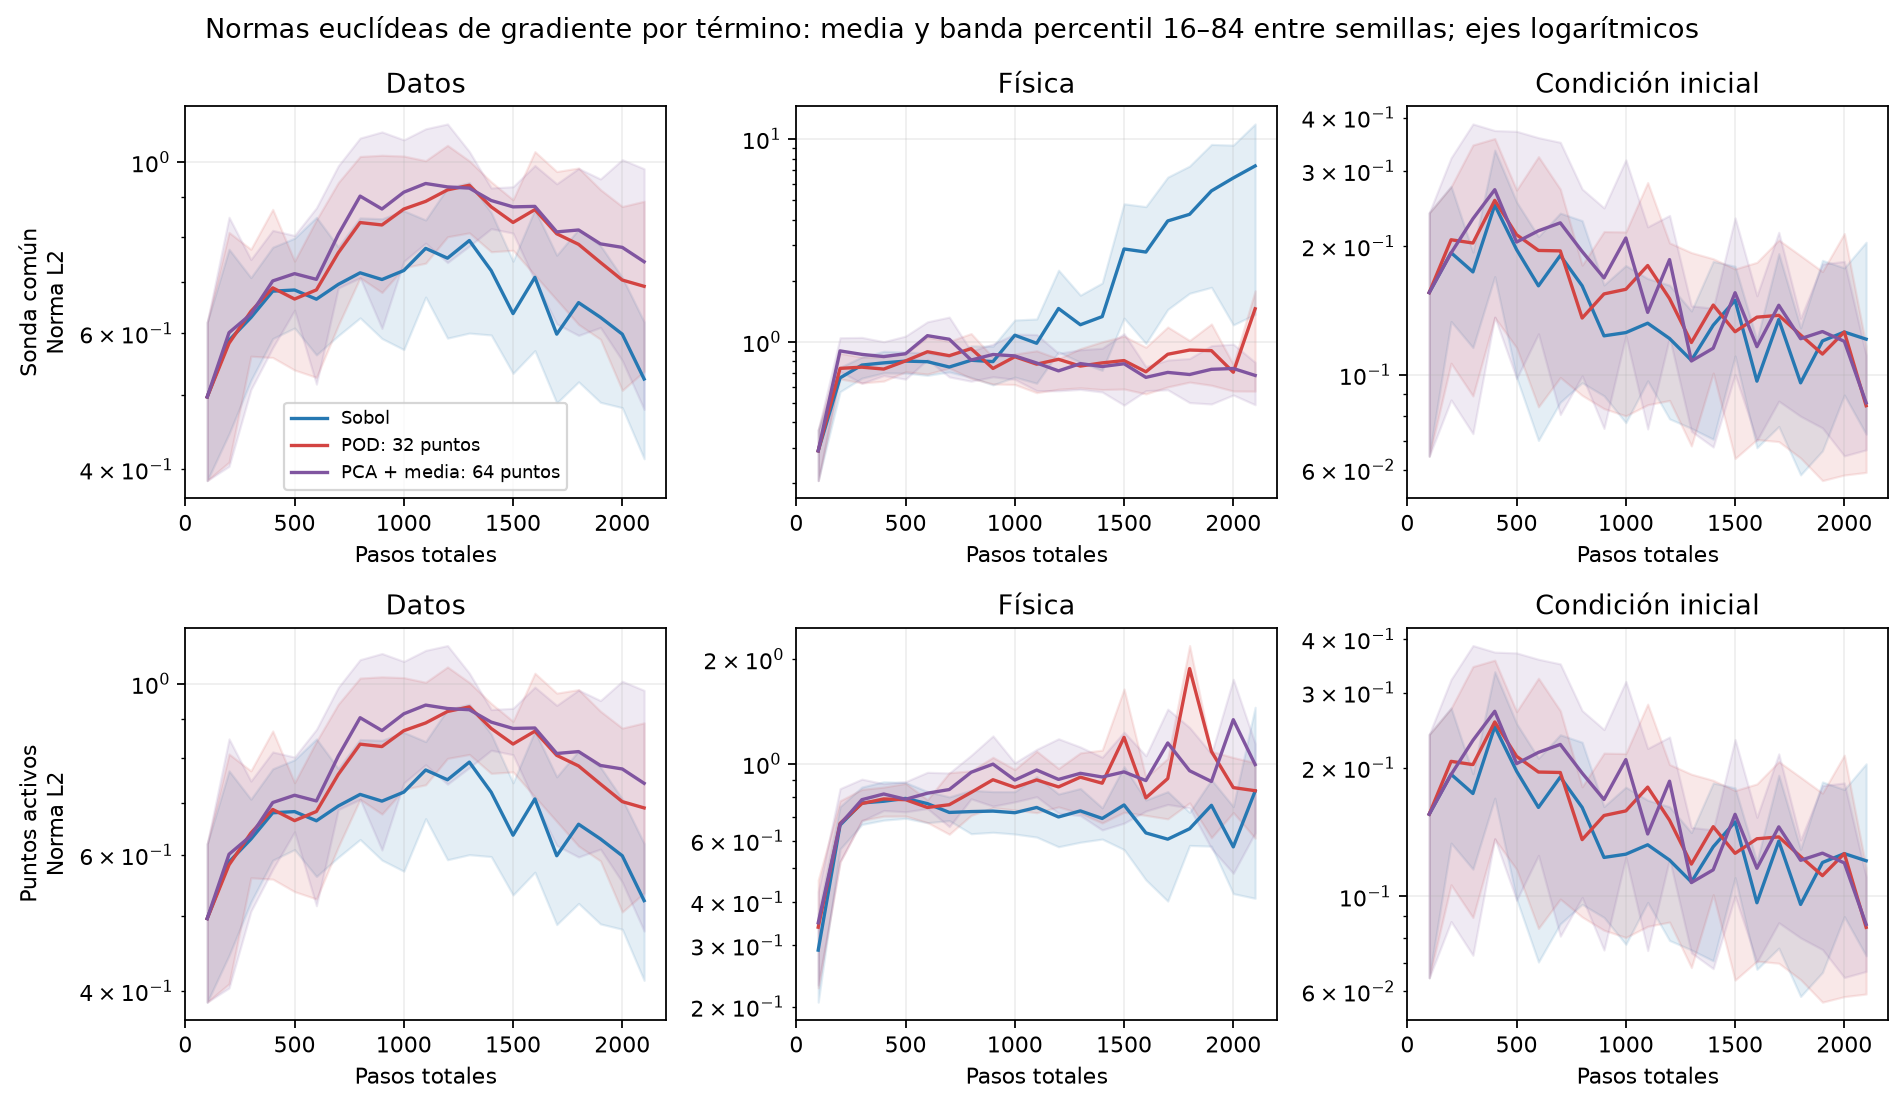

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/grad_components.png'), format='png', embed=True))


**Conflicto entre física y supervisión**

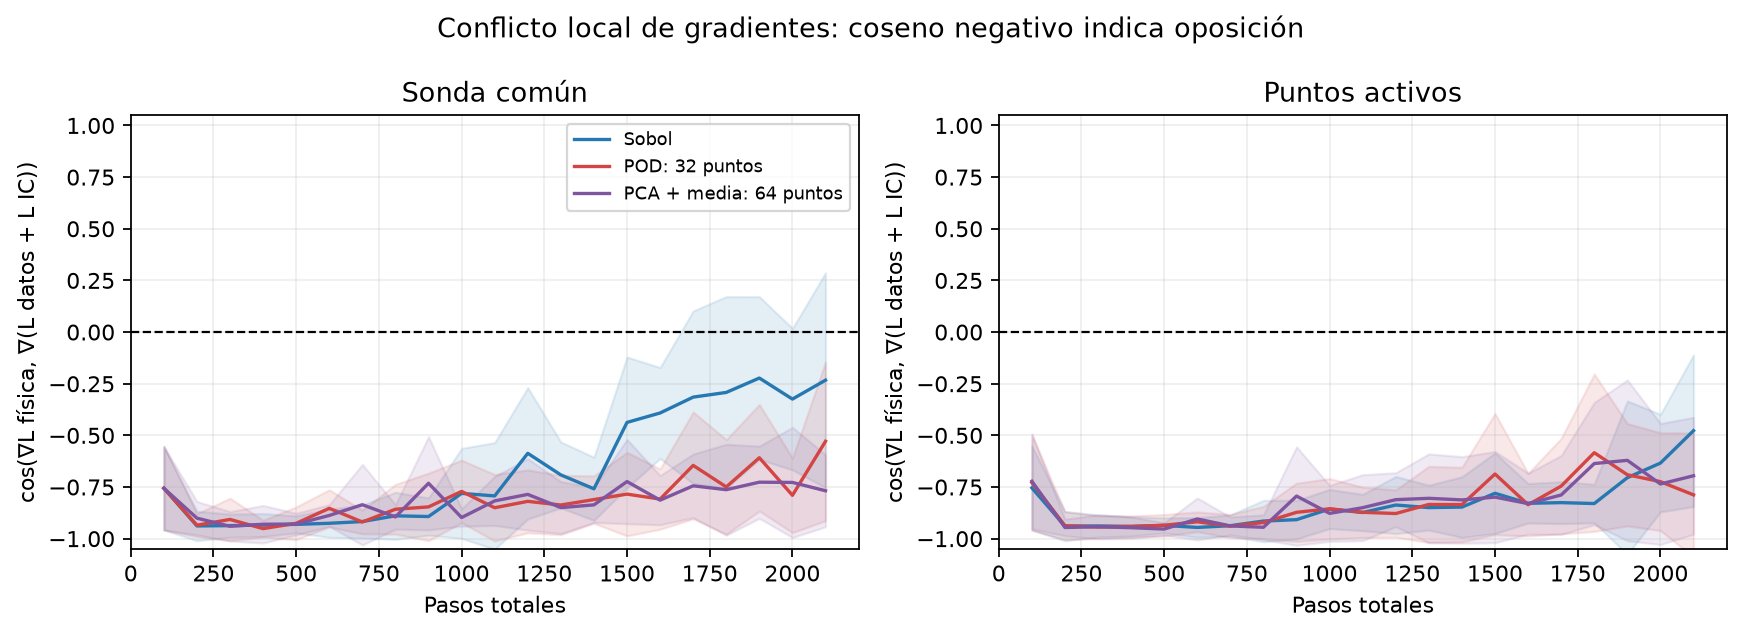

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/gradient_conflict.png'), format='png', embed=True))


## 6. Dónde se concentran los puntos

Las estrellas son puntos del conjunto candidato elegidos por los modos; los puntos grises son el complemento Sobol. Todos los lotes contienen 128 puntos. El paso del título es el momento de selección: ese lote se usa en las siguientes 100 actualizaciones. El rectángulo discontinuo marca la ventana central tardía definida anteriormente.

**Evolución de la selección de puntos**

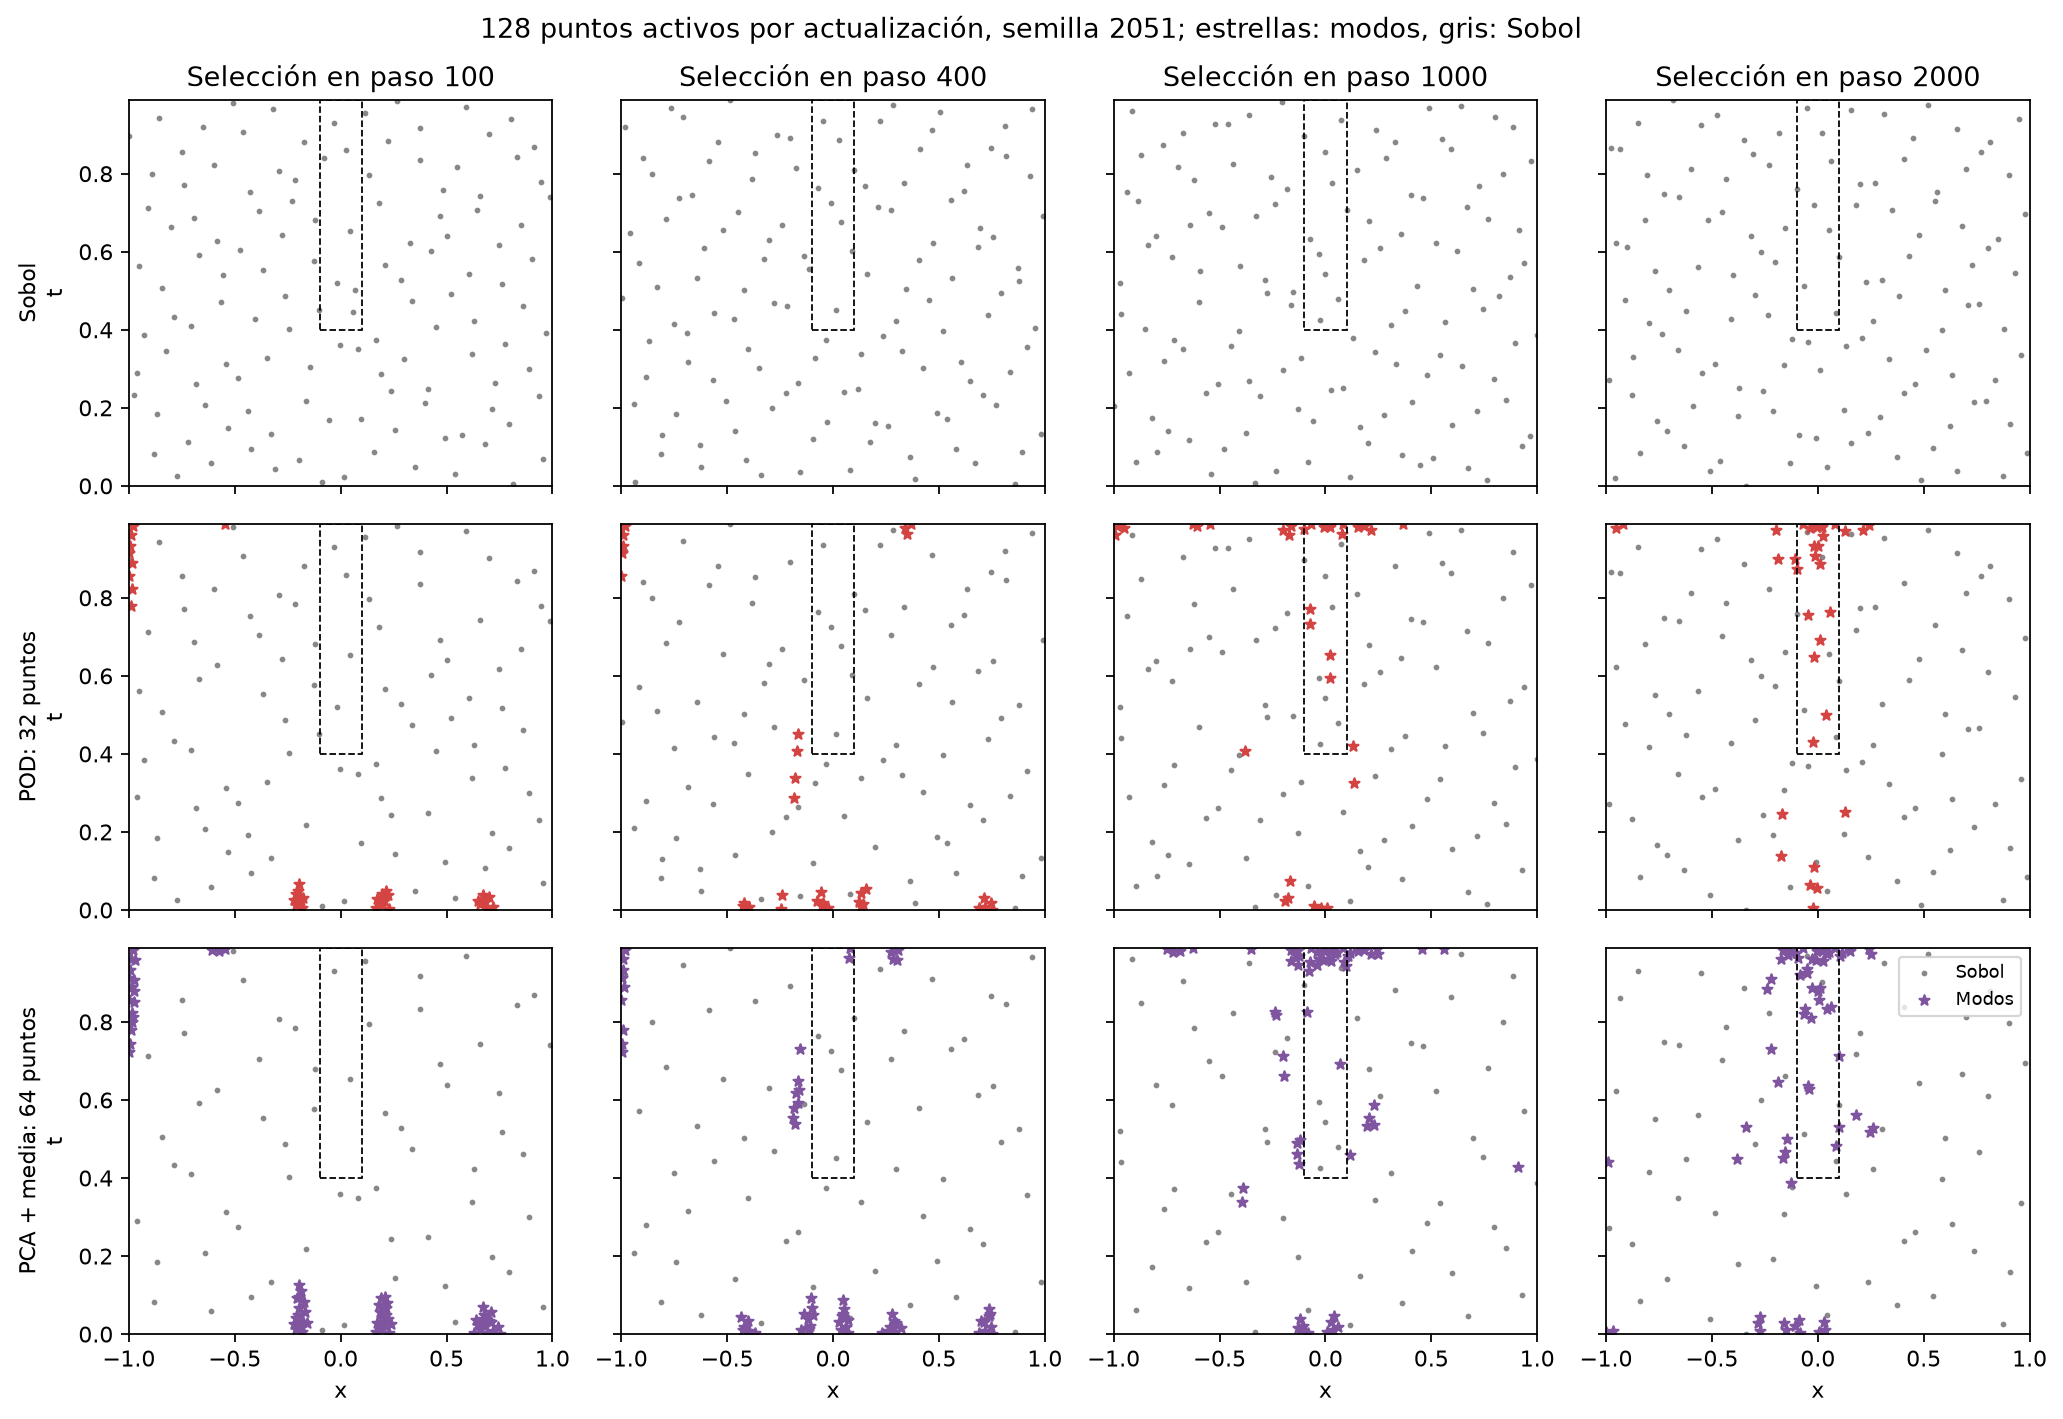

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/selected_points_evolution.png'), format='png', embed=True))


La cobertura se resume con fracción del lote en la ventana, fracción de celdas de una partición 8×8 que contienen puntos y percentil 95 de la distancia desde los puntos independientes al punto activo más cercano. Las distancias usan coordenadas x,t normalizadas por los anchos del dominio; menor distancia indica mejor cobertura según esa métrica, no mejor precisión garantizada. La fracción de puntos de modos no está definida para Sobol puro y su curva se omite.

**Cobertura durante el entrenamiento**

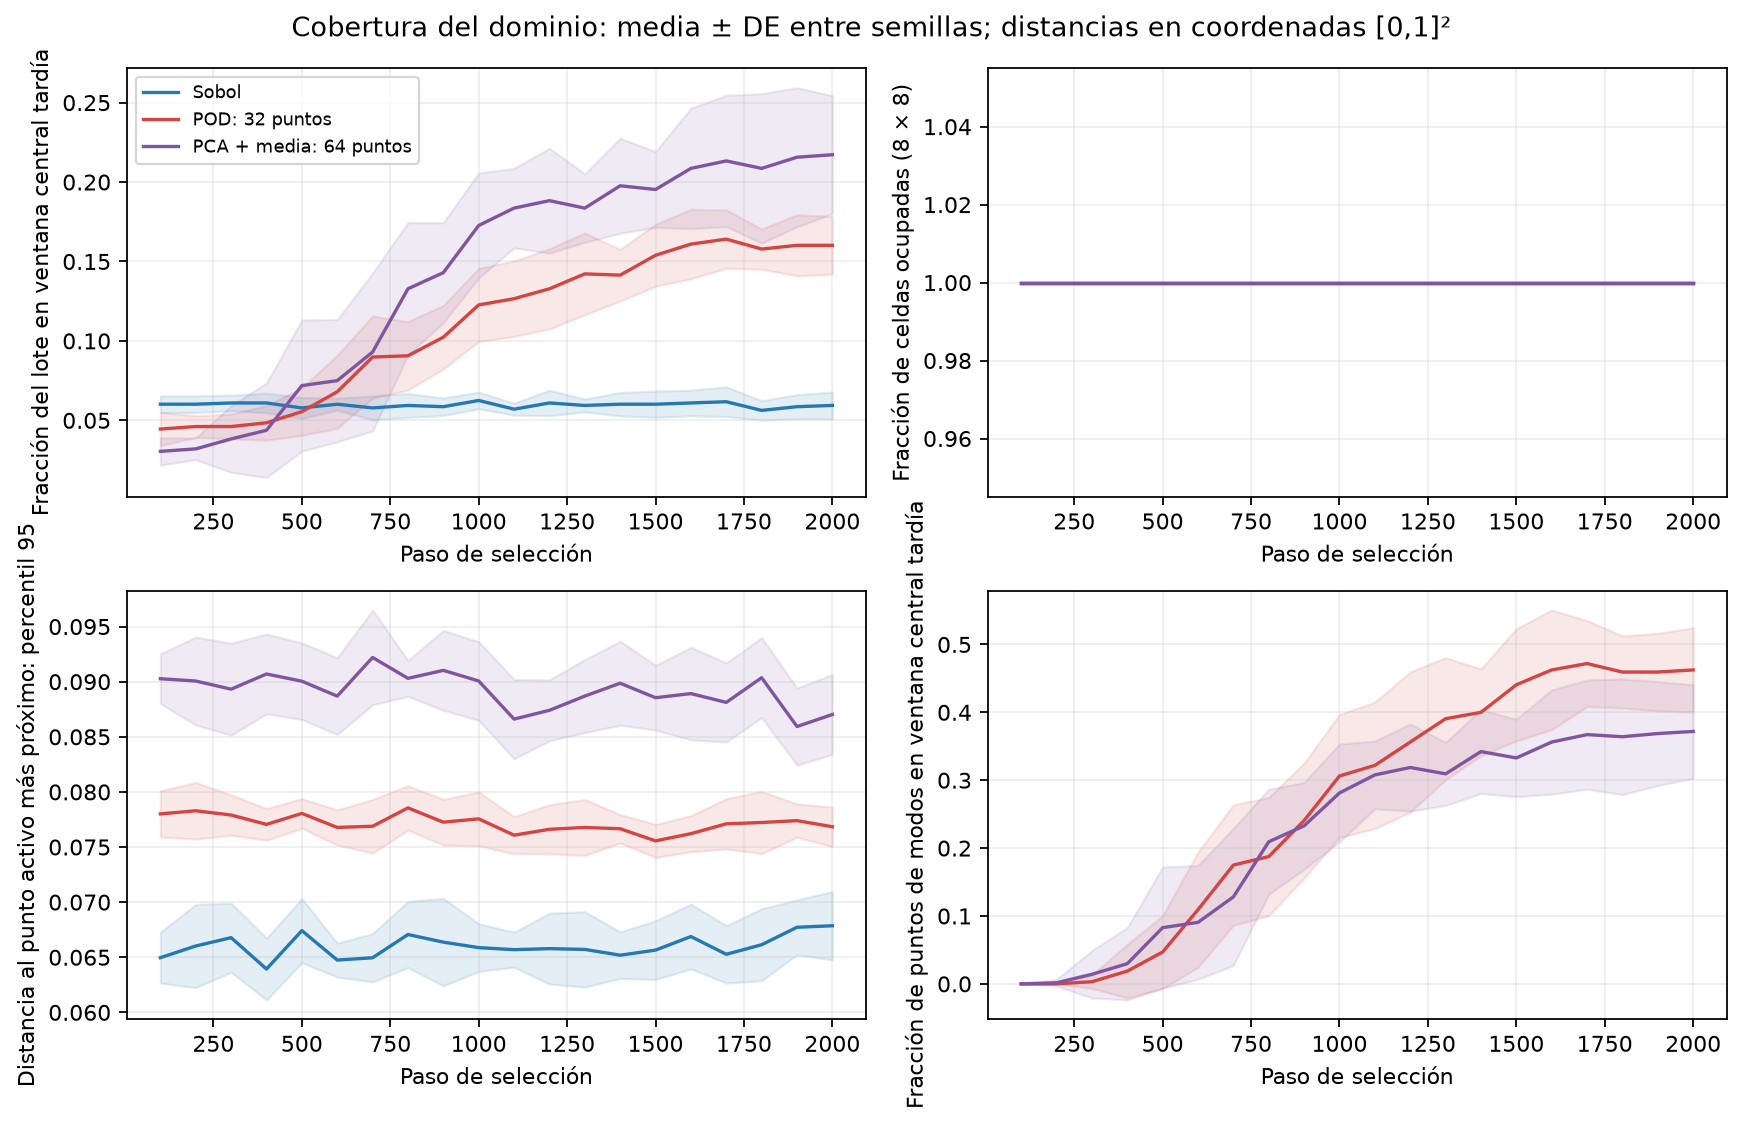

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/coverage_evolution.png'), format='png', embed=True))


## 7. Monitores independientes y evolución de los campos

El error IC de esta figura usa **todos** los nodos espaciales; la L_IC de la sección 4 usa solo los primeros nodos entrenados. La frontera se evalúa en tiempos de validación y permanece fuera de la pérdida explícita. Estas diferencias permiten identificar mejoras locales que no se trasladan al resto del dominio.

**Monitores independientes del selector**

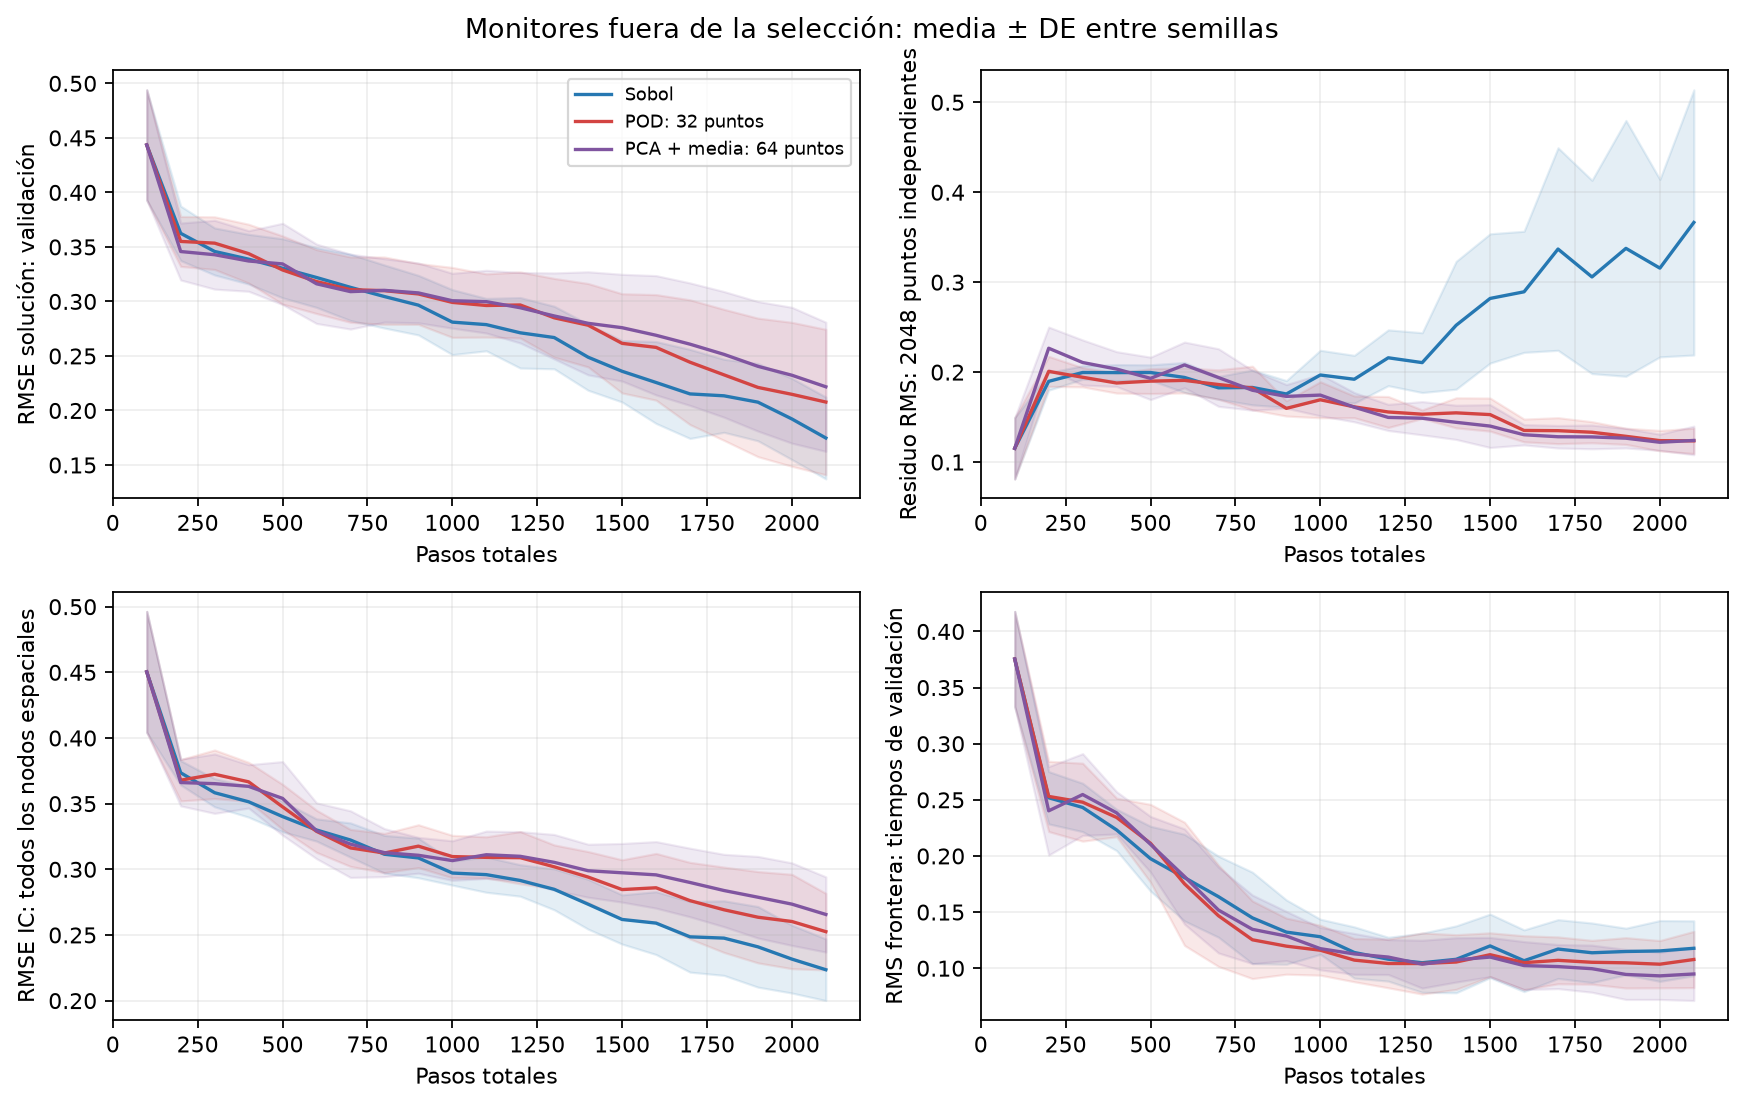

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/independent_monitors.png'), format='png', embed=True))


### Campos en paso 100

**Campos y errores en paso 100**

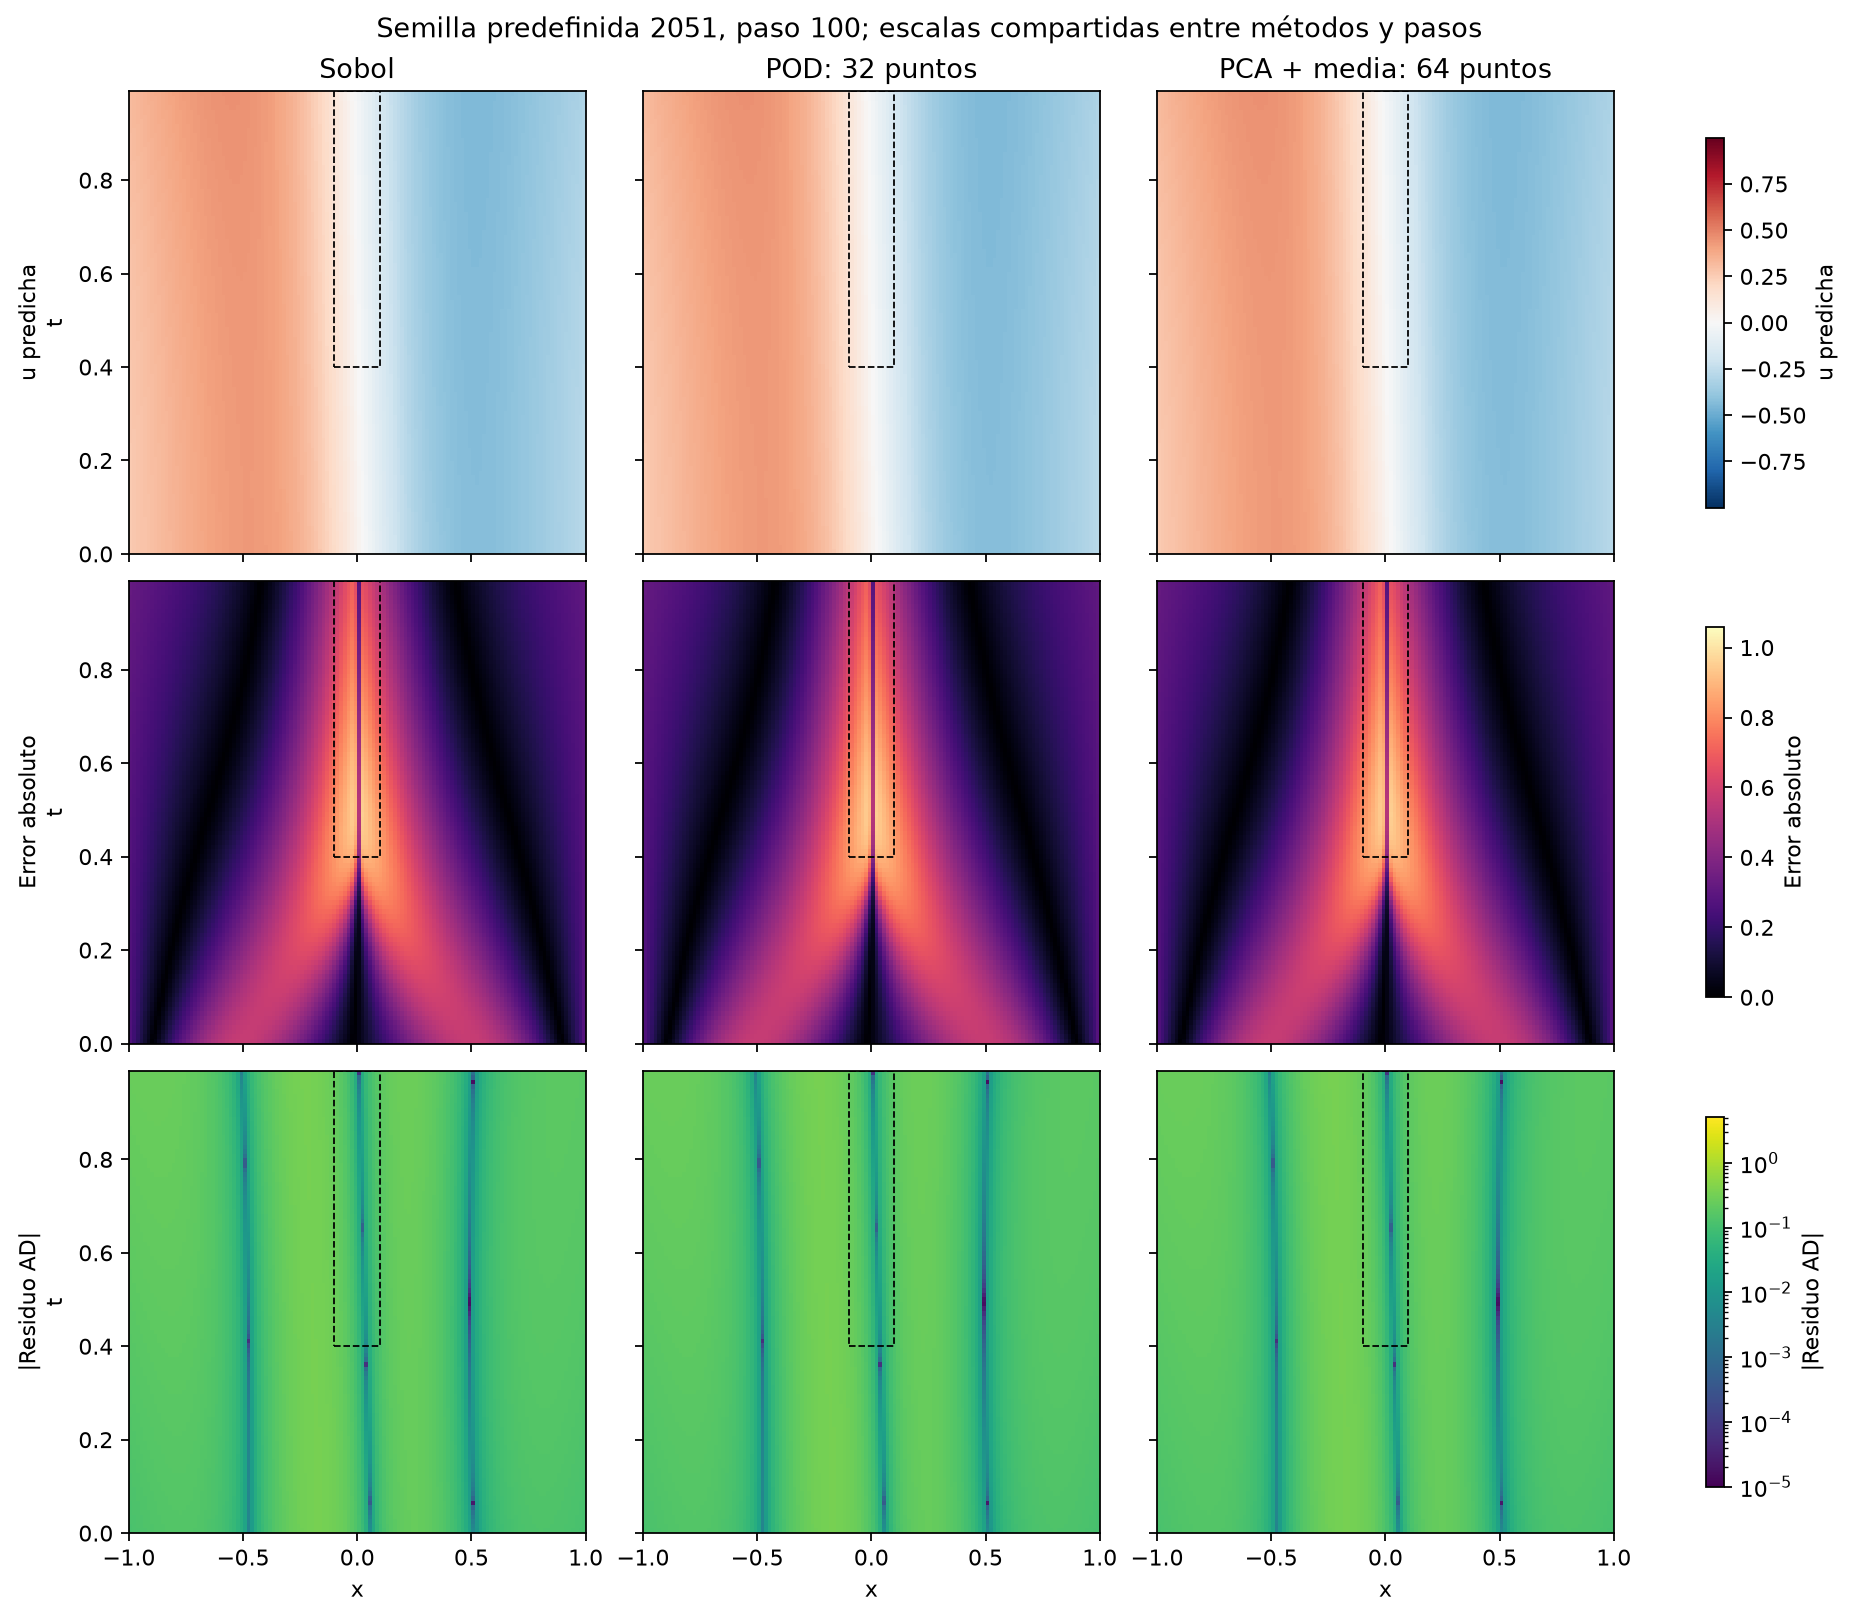

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/fields_step_100.png'), format='png', embed=True))


### Campos en paso 400

**Campos y errores en paso 400**

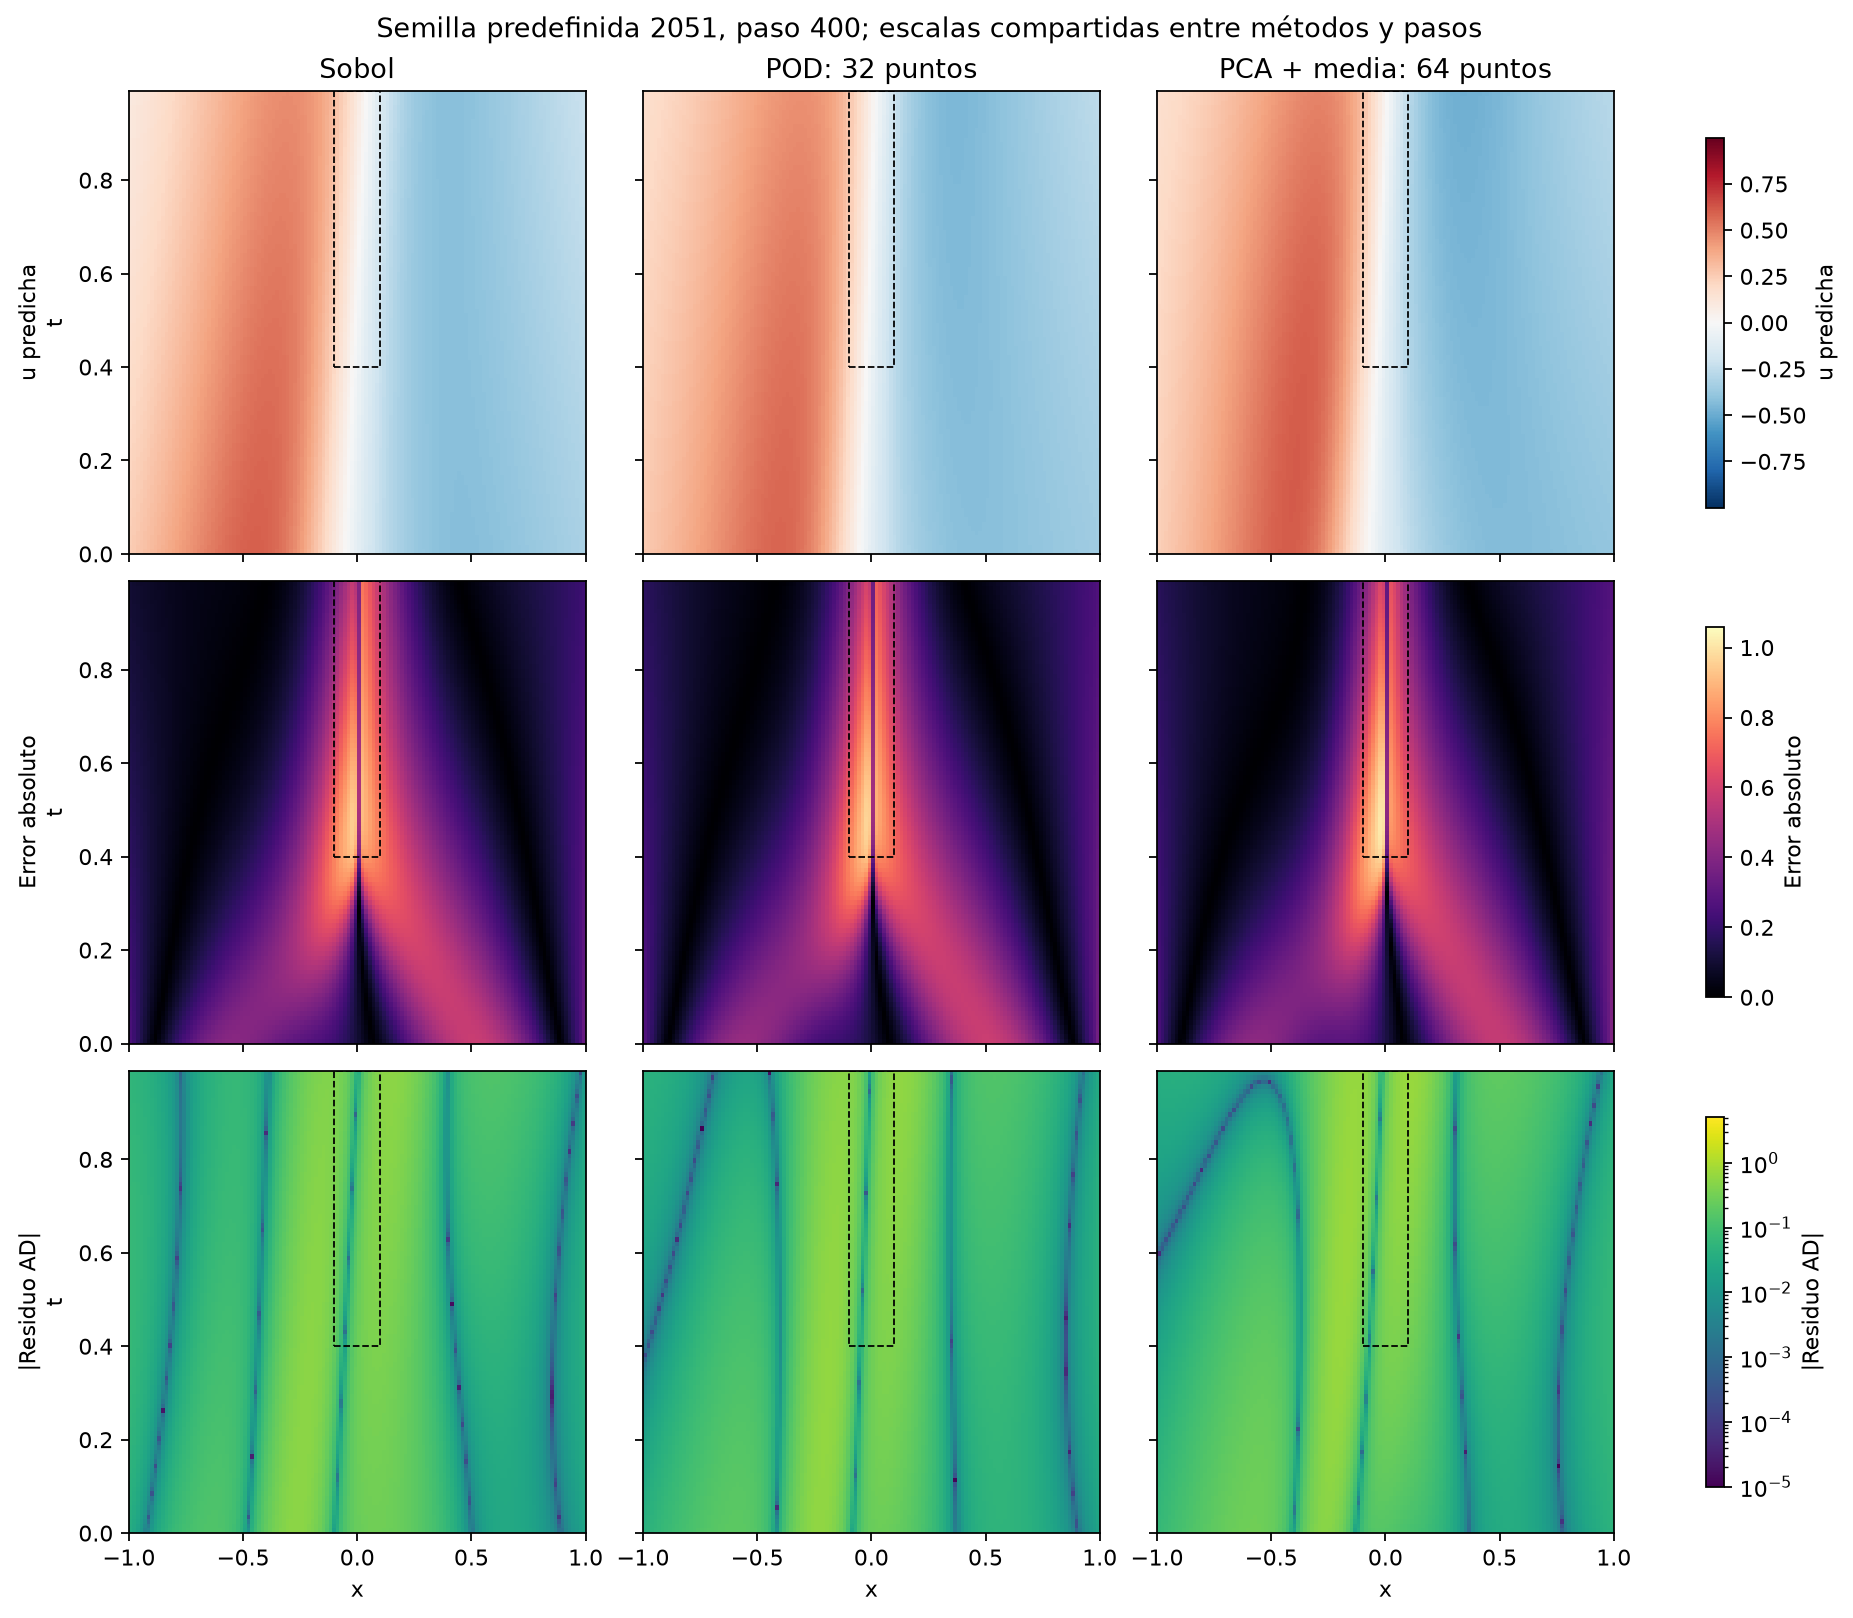

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/fields_step_400.png'), format='png', embed=True))


### Campos en paso 1100

**Campos y errores en paso 1100**

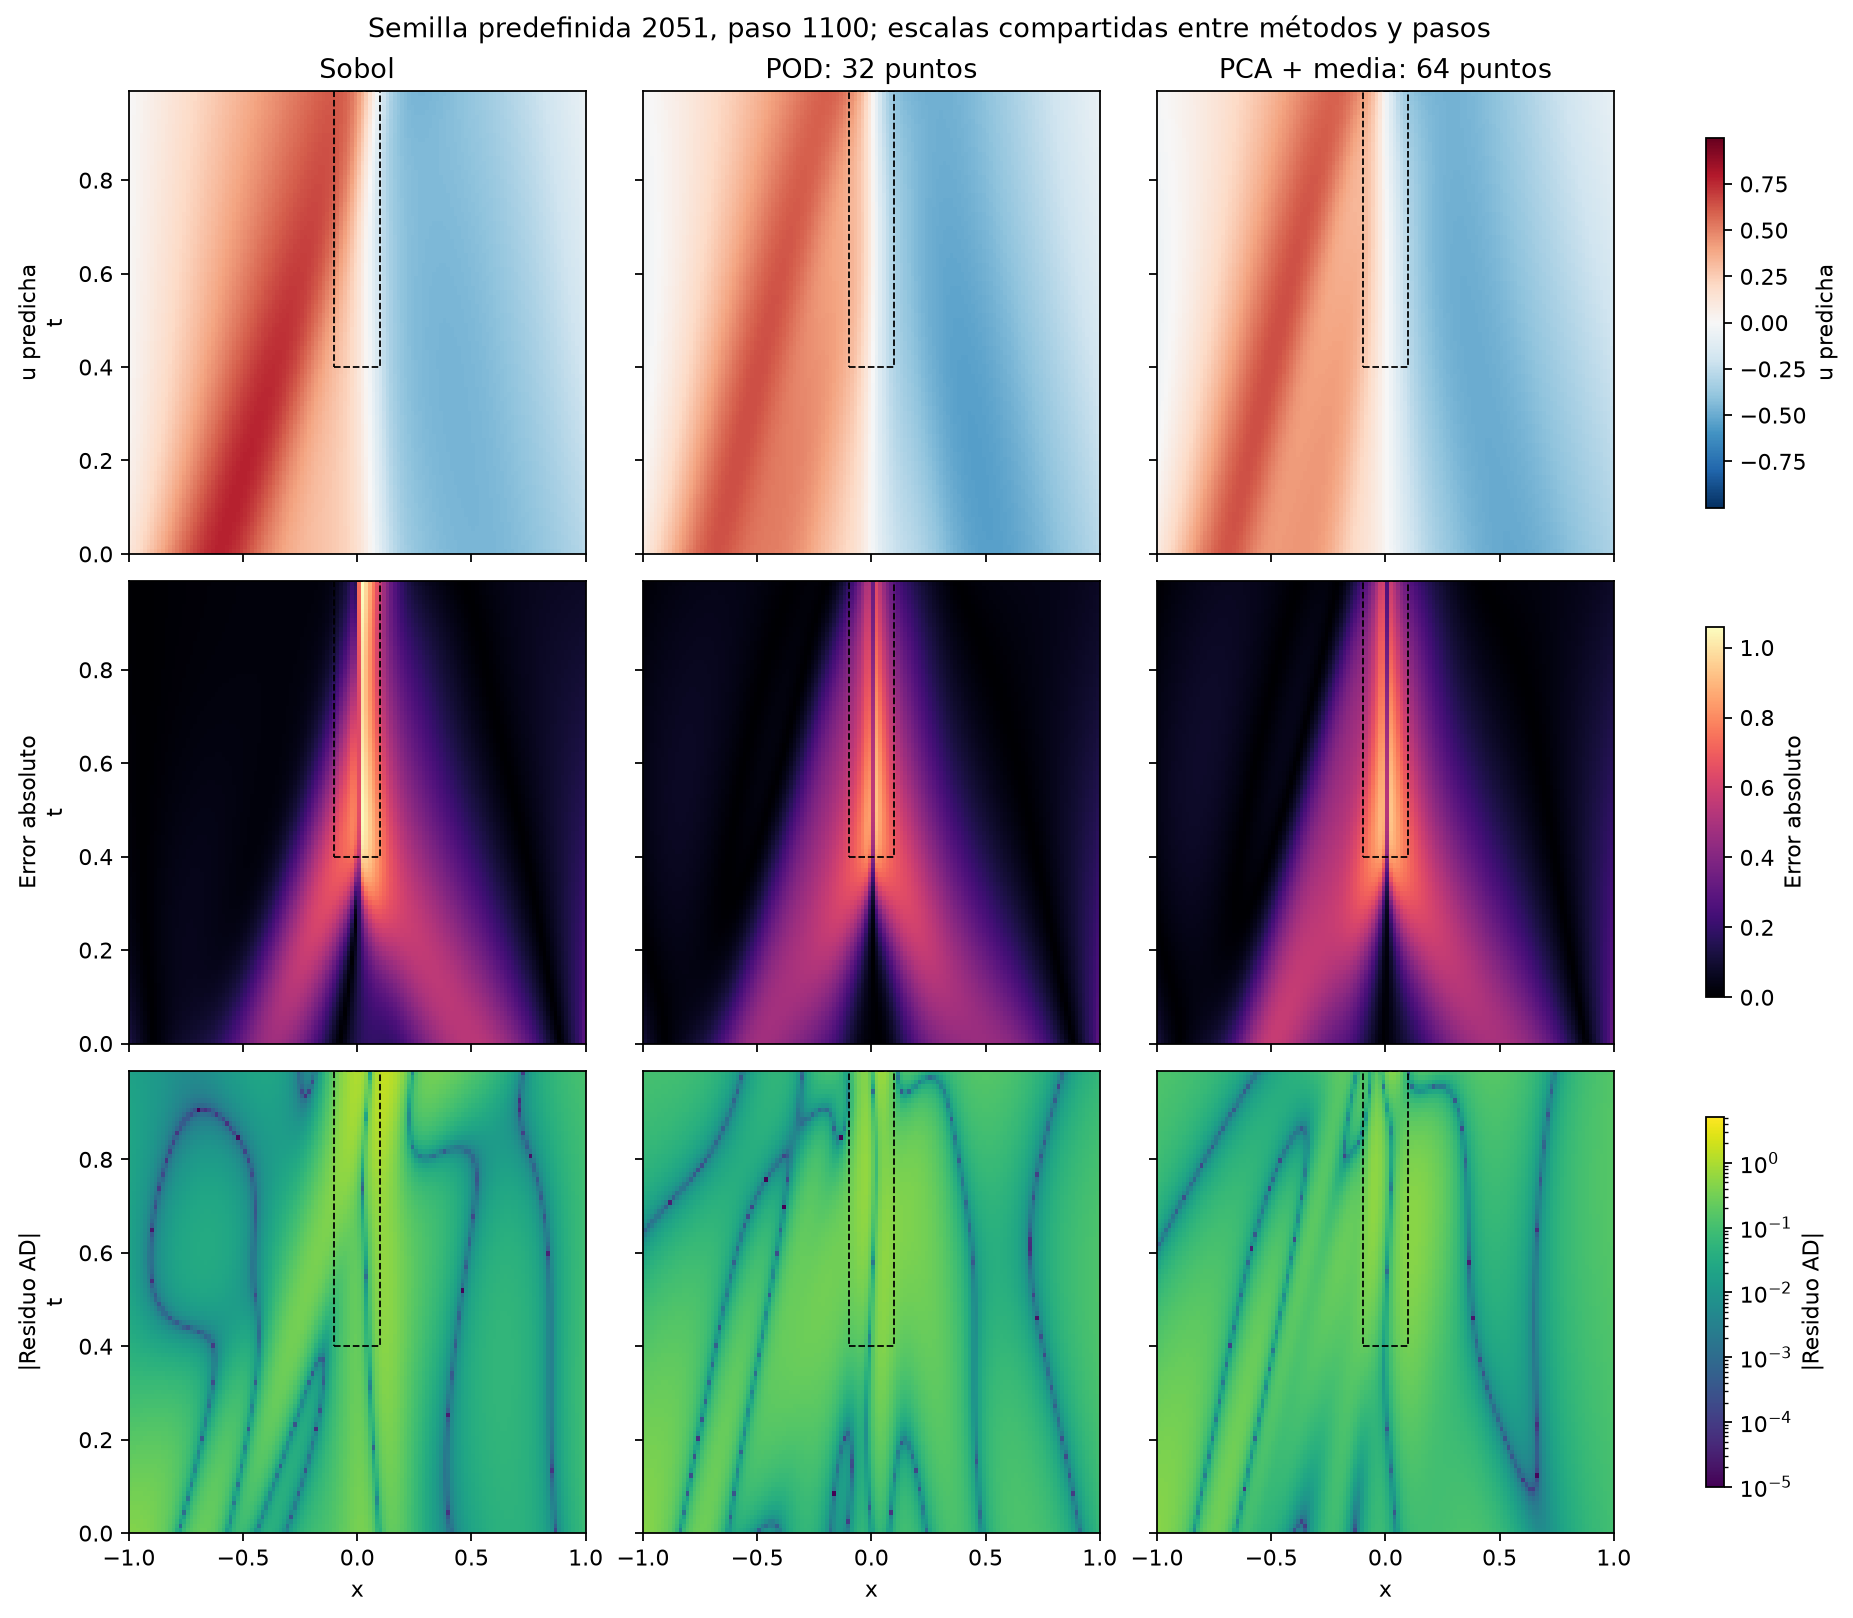

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1/fields_step_1100.png'), format='png', embed=True))


## 8. Qué permite concluir este diagnóstico

**Observaciones de esta corrida:**

| Método | Lote final en ventana central tardía | RMSE de prueba en esa ventana | Controles con oposición de gradientes |
|---|---:|---:|---:|
| Sobol | 5.9% | 0.3736 | 93.5% |
| POD: 32 puntos | 16.0% | 0.4352 | 99.5% |
| PCA + media: 64 puntos | 21.7% | 0.4699 | 100.0% |

POD/PCA concentra una fracción mayor de sus puntos en la ventana central tardía; eso no se traduce en menor error medio de solución en esa ventana. La oposición de gradientes aparece también con Sobol: su sola presencia no explica las diferencias entre métodos.

La media del cociente final de normas física/(datos+IC) en la sonda común es Sobol: 19.20; POD: 32 puntos: 2.95; PCA + media: 64 puntos: 1.00. Su dispersión está en la tabla de gradientes. Estos datos no respaldan reducir la explicación a que el gradiente físico sea siempre mayor con POD/PCA.

El percentil 95 de la distancia de cobertura, promediado entre semillas, es Sobol: 0.0679; POD: 32 puntos: 0.0768; PCA + media: 64 puntos: 0.0870. La ocupación 8×8 alcanza el 100% en el último lote de los tres métodos; esa partición gruesa no distingue su cobertura.

**Hipótesis por contrastar:** cambiar la distribución de puntos físicos puede cambiar el equilibrio entre el ajuste supervisado y el residuo. Un coseno negativo o una norma grande apoyan un posible mecanismo local, pero no demuestran que ese mecanismo cause la diferencia final. La cobertura parcial de IC es además una limitación concreta del protocolo.

Para atribuir causalidad hace falta una ablación que cambie una sola cosa. El control siguiente más directo es distribuir los mismos 32 nodos de IC por todo el dominio, manteniendo métodos, pesos, semillas y presupuesto. Después podría estudiarse el peso físico, con una selección definida por validación. El subconjunto de prueba y los mapas no deben usarse para escoger esos pesos.

## 9. Archivos y reproducción

Cada `seed_<semilla>/` conserva `fields.npz`, `parameters.npz`, `active_points.csv`, `coverage.csv`, `loss_gradient_probes.csv`, `regional_test_errors.csv` y `diagnostic_protocol.json`, además de las métricas y trazas del entrenador. Los parámetros se guardan por capa en los checkpoints de campos, sin pickle. Los CSV globales agregan las semillas conservando sus identificadores; `replay_comparison.csv` y `trajectory_replay_comparison.csv` registran las diferencias finales y de las trayectorias contra la referencia. Los tiempos incluyen la instrumentación y no sirven para comparar velocidad con corridas anteriores.

```powershell
python scripts/run_collocation_diagnostics.py
python scripts/run_collocation_diagnostics.py --report-only
```

La segunda orden regenera el reporte desde los artefactos guardados. Las figuras están incrustadas como PNG en este notebook y también se exportan en PNG/SVG.

In [ ]:
import json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
OUT = ROOT / 'pca_collocation/results/burgers/collocation_diagnostics/residual_balance_diagnostics_10_seeds_2k_v1'
summary = json.loads((OUT / 'summary.json').read_text(encoding='utf-8'))
summary['methods']